In [1]:



import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
df.head()


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:

# Check the number of missing values in each column
print(df.isnull().sum())

# Display columns that contain missing values
print("\nColumns with missing values:")
print(df.columns[df.isnull().any()])


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing values:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')


In [3]:

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns

# Fill missing numerical values with the median
for col in numerical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the mode
for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values[0])

print("Missing values handled using median and mode.")
print(df.isnull().sum())


Missing values handled using median and mode.
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [4]:

# Remove rows with any remaining missing values
df.dropna(inplace=True)

# Verify the result
print("Remaining missing values:")
print(df.isnull().sum())

print("\nDataset shape after handling missing values:")
print(df.shape)


Remaining missing values:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Dataset shape after handling missing values:
(6433, 14)


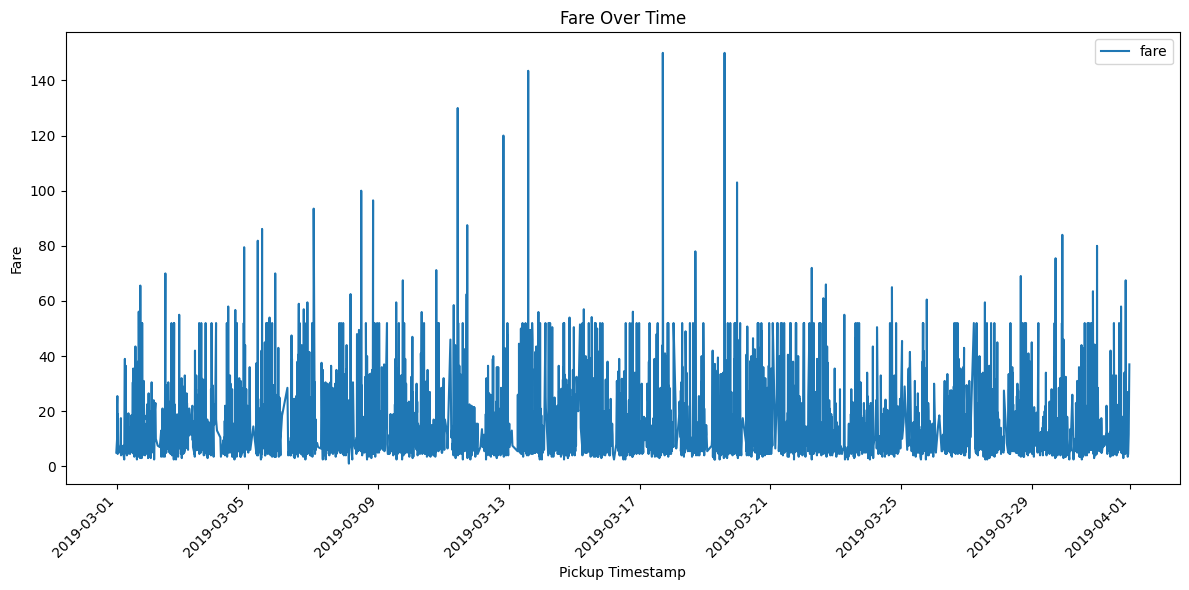

In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert pickup column to datetime format
df["pickup"] = pd.to_datetime(df["pickup"])

# Sort data by pickup time
df = df.sort_values("pickup")

# Create a line chart
df.plot(x="pickup", y="fare", kind="line", figsize=(12, 6))

# Add title and labels
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart
plt.show()


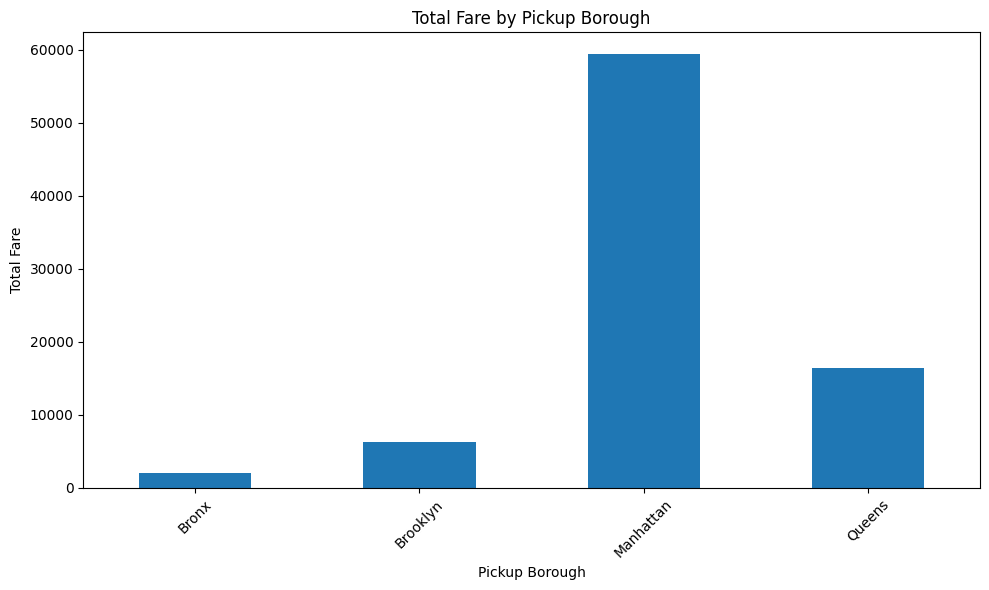

In [6]:

# Group data by pickup borough and calculate total fare
borough_fare = df.groupby("pickup_borough")["fare"].sum()

# Create a bar chart
borough_fare.plot(kind="bar", figsize=(10, 6))

# Add title and labels
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart
plt.show()


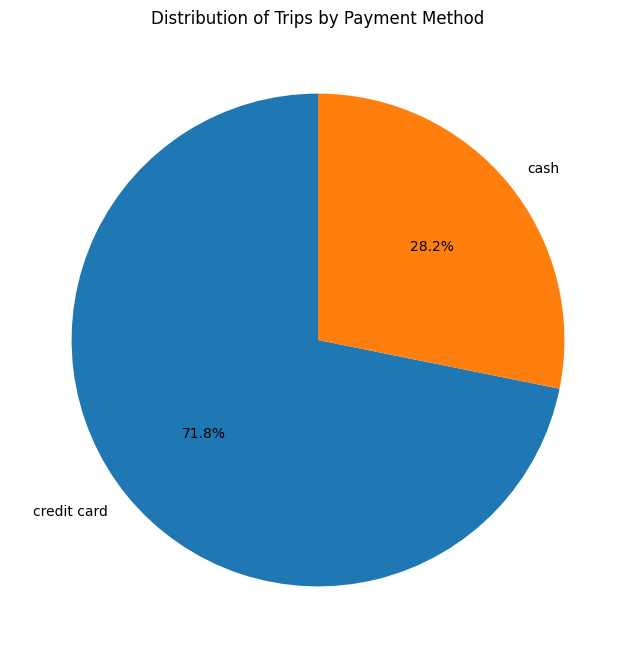

In [7]:

import matplotlib.pyplot as plt

# Count trips for each payment method
payment_counts = df["payment"].value_counts()

# Create a pie chart
payment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8, 8),
    startangle=90
)

# Add title
plt.title("Distribution of Trips by Payment Method")
plt.ylabel("")

# Display the chart
plt.show()


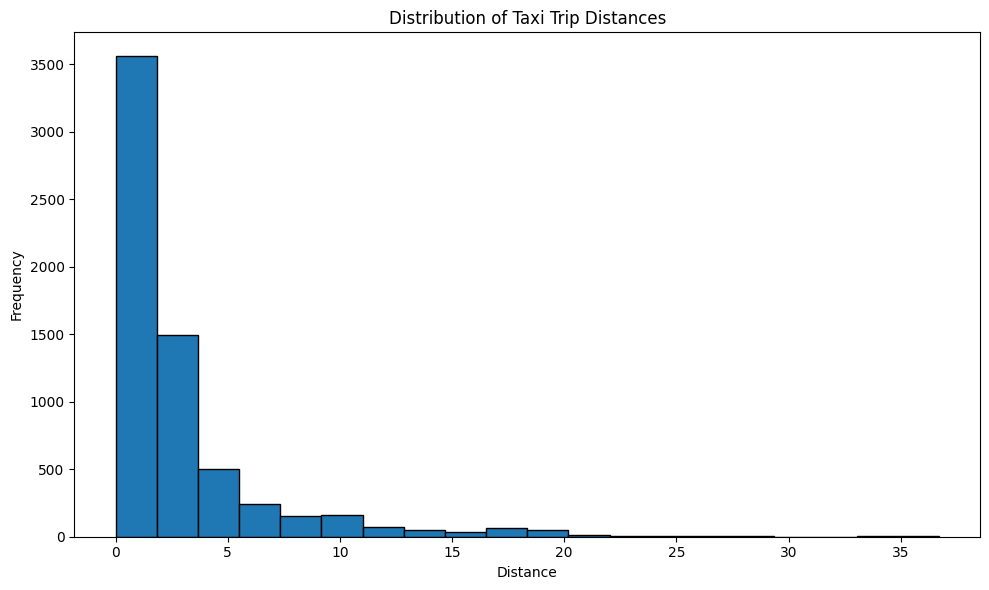

In [8]:

# Create a histogram of trip distances
df["distance"].dropna().plot(
    kind="hist",
    bins=20,
    figsize=(10, 6),
    edgecolor="black"
)

# Add title and labels
plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance")
plt.ylabel("Frequency")

# Display the chart
plt.tight_layout()
plt.show()


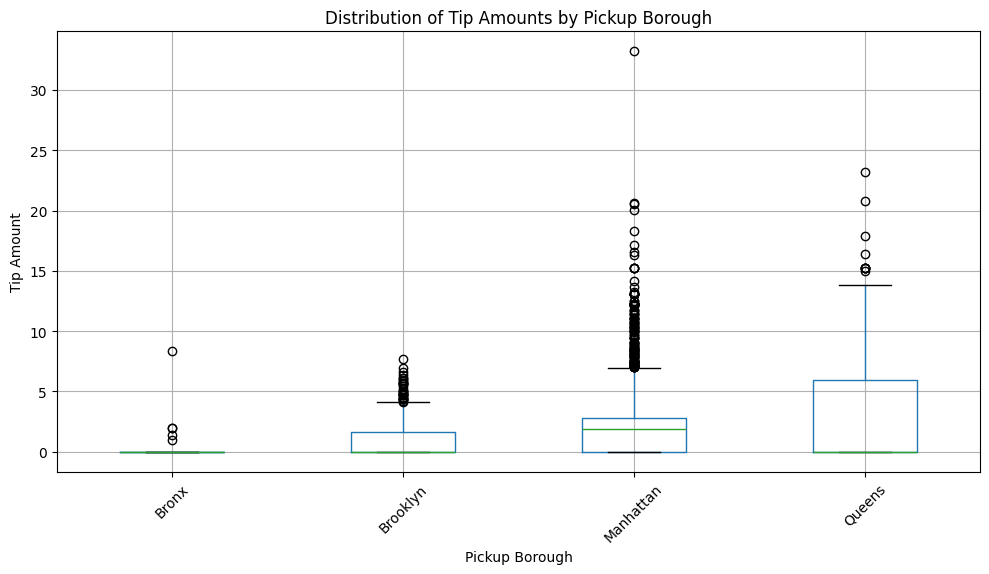

In [9]:

# Prepare data for the box plot
box_data = df.dropna(subset=["pickup_borough", "tip"])

# Create a box plot for tips in each pickup borough
box_data.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(10, 6)
)

# Add title and labels
plt.title("Distribution of Tip Amounts by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()


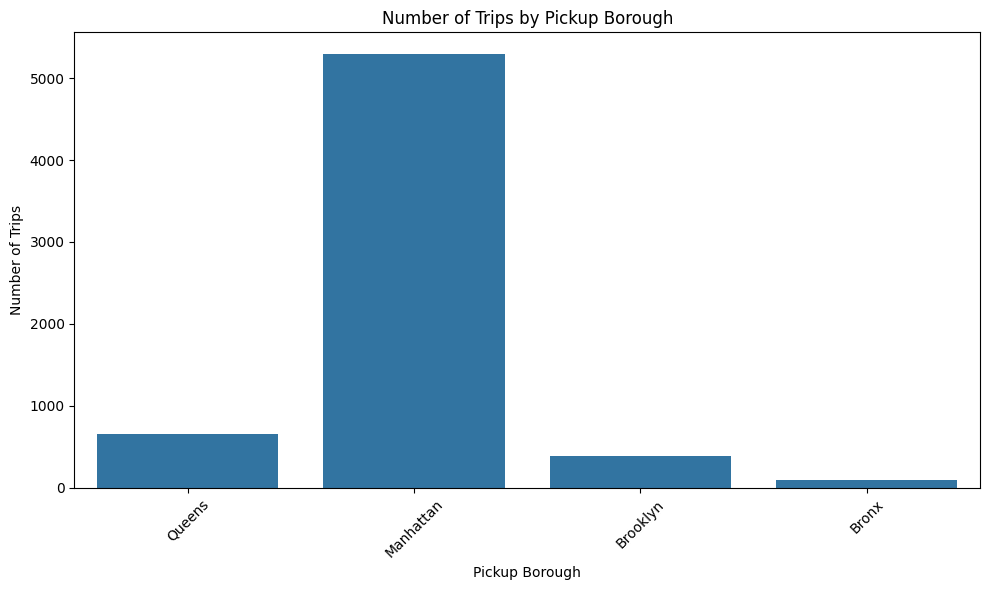

In [10]:

import seaborn as sns
import matplotlib.pyplot as plt

# Create a count plot
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


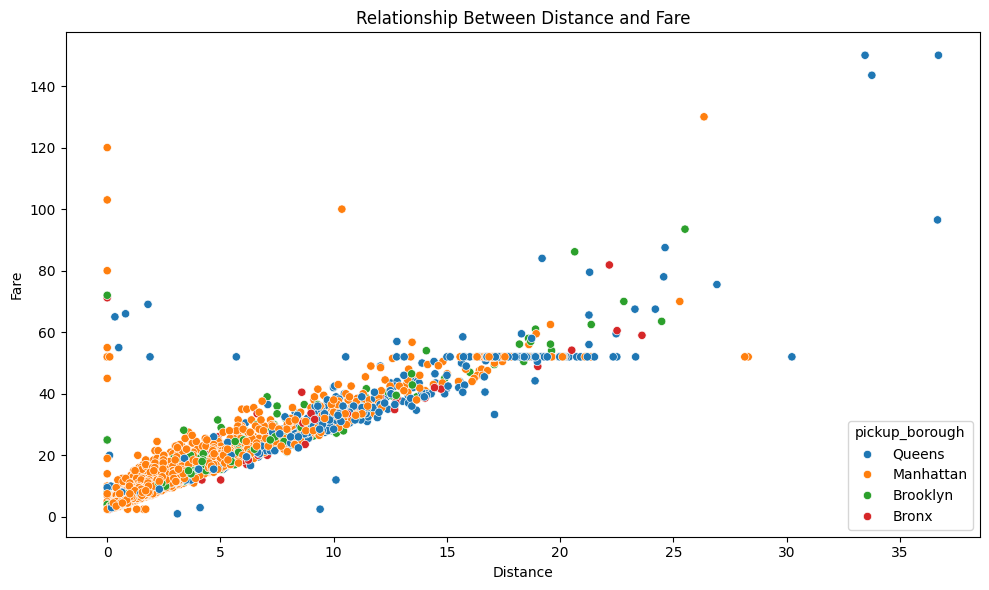

In [11]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()


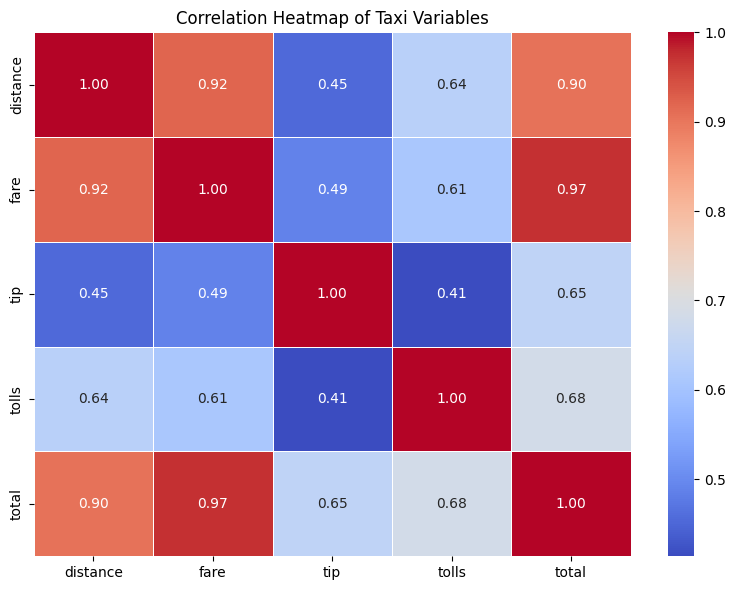

In [12]:

# Select numerical columns
numeric_data = df[["distance", "fare", "tip", "tolls", "total"]]

# Calculate the correlation matrix
correlation_matrix = numeric_data.corr()

# Create the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Taxi Variables")
plt.tight_layout()
plt.show()


In [3]:

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the taxis dataset again
df = sns.load_dataset("taxis")

# Check the dataset
print(df.head())


               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

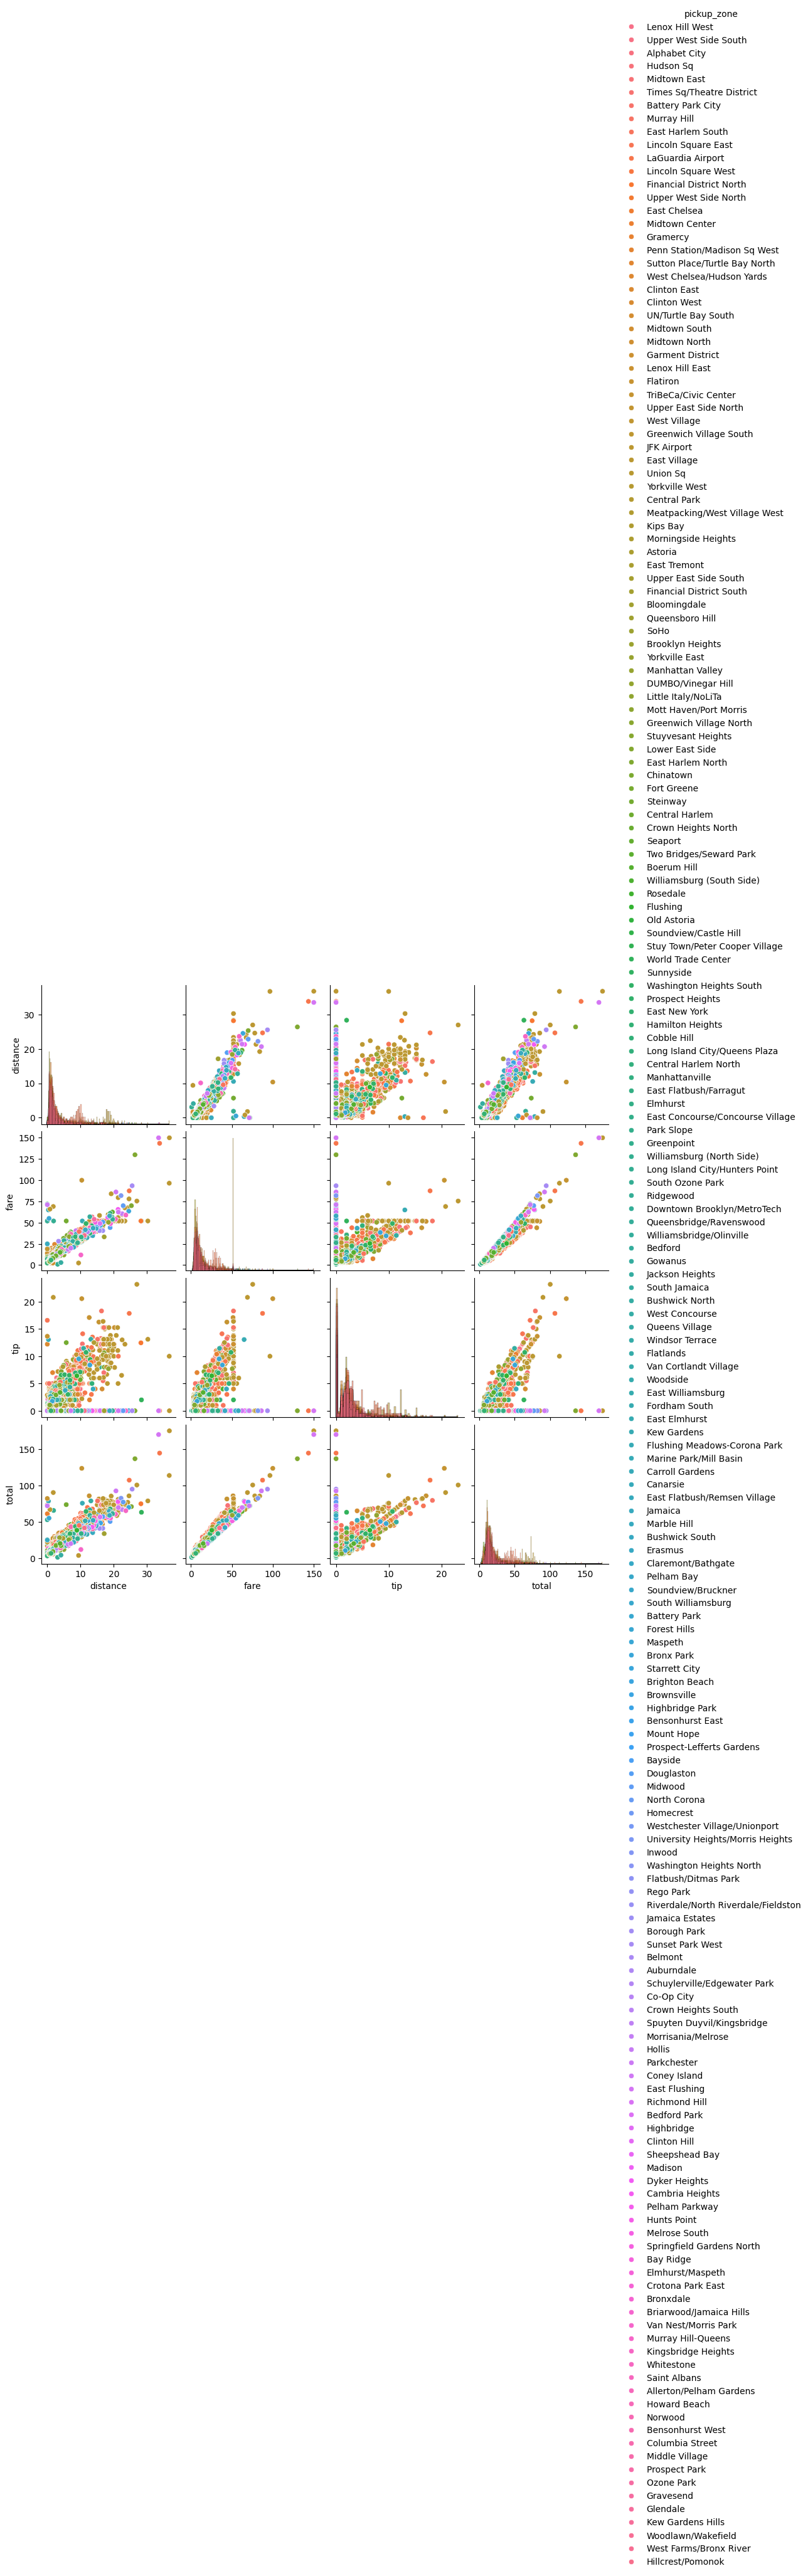

In [4]:

# Select the required columns and remove missing values
pair_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

# Create the pair plot
sns.pairplot(
    data=pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.show()


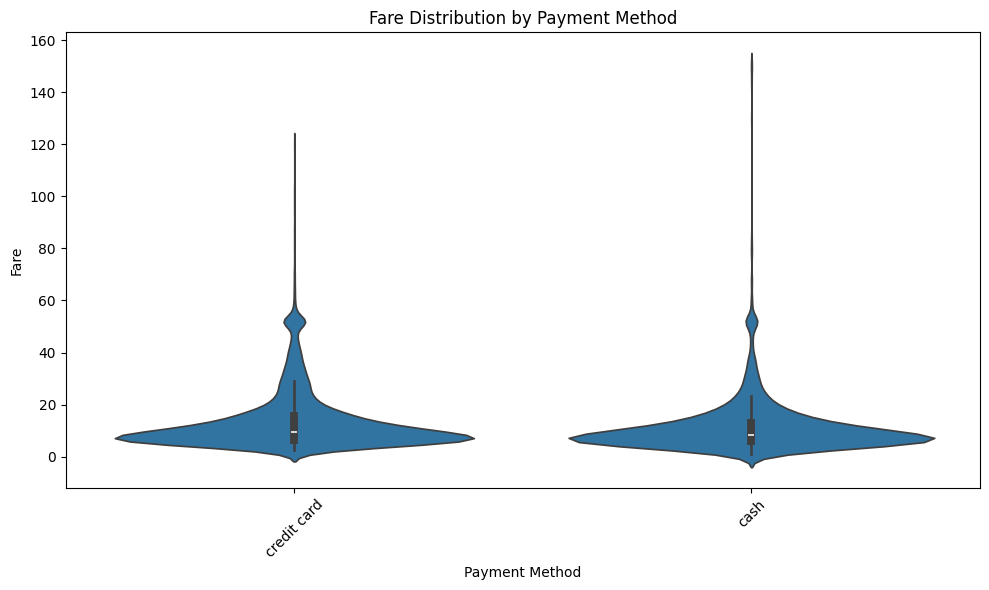

In [5]:

# Remove rows missing payment method or fare
violin_data = df.dropna(subset=["payment", "fare"])

# Create the violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=violin_data,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
